# wav2vec2 Layerwise Analysis — Normal vs Dysarthric Speech (UASpeech)

Same layerwise LOSO probing as in `wav2vec_analysis.ipynb`, applied to the
**UASpeech** corpus (Kim et al., IS2008): isolated words from speakers with
Cerebral Palsy vs. matched controls.

| Split | Speakers | Label |
|---|---|---|
| `UASpeech_C/audio/original/` | CF02–CF05, CM01, CM04–CM06, CM08–CM10, CM12, CM13 (13 speakers) | 0 = normal |
| `UASpeech_FM/audio/original/` | F02–F05, M01, M04–M05, M07–M12, M14, M16 (15 speakers) | 1 = dysarthric |

**Microphone**: M3 only (7-mic array; M3 is the standard single-mic choice in the literature).  
**Total**: ~21 000 utterances, 28 speakers, LOSO = 28 folds.  
**Cache**: `wav2vec_features_uaspeech.npz`


## 1.  Imports & Setup

In [3]:
import os, re, numpy as np, matplotlib.pyplot as plt
import librosa, torch
from transformers import Wav2Vec2FeatureExtractor, Wav2Vec2Model
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import accuracy_score, classification_report
from sklearn.manifold import TSNE
from tqdm.notebook import tqdm

plt.rcParams.update({"figure.dpi": 120})
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")


Using device: cuda


## 2.  Load wav2vec2 Model

`facebook/wav2vec2-base-960h` was pretrained on 960 h of LibriSpeech.

**Architecture recap:**

| Component | What it does | Output dim |
|---|---|---:|
| CNN feature encoder (7 layers) | raw waveform → local acoustic frames at ~20 ms stride | 512 |
| Linear projection | projects CNN output into transformer space | 768 |
| Transformer (12 layers) | contextualises frames via self-attention | 768 |

Setting `output_hidden_states=True` gives us the projected CNN output
+ all 12 transformer layer outputs = **13 hidden states** in total.
We mean-pool each over time → one 768-dim vector per utterance per layer.


In [4]:
feature_extractor = Wav2Vec2FeatureExtractor.from_pretrained("facebook/wav2vec2-base-960h")
model = Wav2Vec2Model.from_pretrained("facebook/wav2vec2-base-960h")
model = model.to(DEVICE)
model.eval()
print("Model loaded.")
print(f"Number of transformer layers: {model.config.num_hidden_layers}")
print(f"Hidden size: {model.config.hidden_size}")

Some weights of Wav2Vec2Model were not initialized from the model checkpoint at facebook/wav2vec2-base-960h and are newly initialized: ['masked_spec_embed']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Model loaded.
Number of transformer layers: 12
Hidden size: 768


## 3.  Extract All-Layer Features

For each wav file we:
1. Load at 16 kHz
2. Pass through wav2vec2 with `output_hidden_states=True`
3. Mean-pool each of the 13 hidden states over time → one 768-dim vector per layer
4. Store the (13, 768) array per file

Only **M3** recordings are used (one mic per utterance).  
Control speakers (`C` prefix in UASpeech_C) → label 0.  
Dysarthric speakers (`M`/`F` prefix in UASpeech_FM) → label 1.  
Speaker ID is the filename prefix, e.g. `M16_B1_C1_M3.wav` → `M16`.

Intelligibility groups (Kim et al. 2008, % word accuracy by naive listeners):

| Group | Speakers | Intelligibility |
|---|---|---|
| Very Low | M01, M04, M07, M08 | < 25 % |
| Low | M05, M09, M10, M11, M12, F02, F04 | 25–50 % |
| Medium | M14, M16, F03 | 50–75 % |
| High | F05 | > 75 % |


In [ ]:
UA_ROOT = os.path.join("UASpeech")
SOURCES = [
    (os.path.join(UA_ROOT, "UASpeech_C",  "audio", "original"), 0),  # control
    (os.path.join(UA_ROOT, "UASpeech_FM", "audio", "original"), 1),  # dysarthric
]
MIC      = "M6"         
CACHE    = "cache_files/wav2vec_features_uaspeech_m6.npz"
SR       = 16_000
MAX_SECS = 10.0           # skip any file longer than this

# Severity groups 
SEVERITY = {
    "M01": "very_low", "M04": "very_low", "M07": "very_low", "M08": "very_low",
    "M05": "low",      "M09": "low",      "M10": "low",
    "M11": "medium",   "M12": "medium",   "M16": "medium",
    "F02": "high",     "F03": "high",     "F04": "high",     "F05": "high",  "M14": "high",
}

os.makedirs("cache_files", exist_ok=True)
if os.path.exists(CACHE):
    print("Loading features from cache...")
    data        = np.load(CACHE, allow_pickle=True)
    all_hidden  = data["all_hidden"]
    y_all       = data["labels"]
    speaker_ids = data["speaker_ids"].tolist()
    print(f"Loaded: {all_hidden.shape[0]} samples, "
          f"{all_hidden.shape[1]} layers, {all_hidden.shape[2]} dims")
    print(f"Speakers: {sorted(set(speaker_ids))}")
else:
    print("Extracting features — running on", DEVICE)
    all_hidden, labels, speaker_ids = [], [], []
    n_skipped = 0

    for folder_root, label in SOURCES:
        for spk in tqdm(sorted(os.listdir(folder_root)), desc=("control" if label==0 else "dysarthric")):
            spk_path = os.path.join(folder_root, spk)
            if not os.path.isdir(spk_path):
                continue
            wav_files = sorted(
                f for f in os.listdir(spk_path)
                if f.endswith(f"_{MIC}.wav")
            )
            for fname in tqdm(wav_files, desc=spk, leave=False):
                fpath = os.path.join(spk_path, fname)
                speaker = fname.split("_")[0]
                try:
                    y, _ = librosa.load(fpath, sr=SR, mono=True)
                    if len(y) / SR > MAX_SECS:   # skip unexpectedly long files
                        n_skipped += 1
                        continue
                    inputs = feature_extractor(
                        y, sampling_rate=SR, return_tensors="pt"
                    ).input_values.to(DEVICE)
                    with torch.no_grad():
                        outputs = model(inputs, output_hidden_states=True)
                    layer_vecs = np.stack([
                        h.squeeze(0).mean(dim=0).cpu().numpy()
                        for h in outputs.hidden_states
                    ])  # (13, 768)
                    all_hidden.append(layer_vecs)
                    labels.append(label)
                    speaker_ids.append(speaker)
                    # free GPU memory after each file
                    del inputs, outputs
                    torch.cuda.empty_cache()
                except RuntimeError as e:
                    if "out of memory" in str(e).lower():
                        torch.cuda.empty_cache()
                        print(f"OOM on {fname}, skipping")
                        n_skipped += 1
                    else:
                        print(f"Skipped {fname}: {e}")
                        n_skipped += 1
                except Exception as e:
                    print(f"Skipped {fname}: {e}")
                    n_skipped += 1

    all_hidden = np.array(all_hidden)   # (N, 13, 768)
    y_all      = np.array(labels)
    np.savez(CACHE,
             all_hidden=all_hidden,
             labels=y_all,
             speaker_ids=np.array(speaker_ids, dtype=object))
    print(f"Saved to {CACHE}  |  shape: {all_hidden.shape}")
    print(f"Speakers: {sorted(set(speaker_ids))}")
    print(f"Normal: {(y_all==0).sum()}  Dysarthric: {(y_all==1).sum()}")
    if n_skipped: 
        print(f"Skipped: {n_skipped} files")


Loading features from cache...
Loaded: 21202 samples, 13 layers, 768 dims
Speakers: ['CF02', 'CF03', 'CF04', 'CF05', 'CM01', 'CM04', 'CM05', 'CM06', 'CM08', 'CM09', 'CM10', 'CM12', 'CM13', 'F02', 'F03', 'F04', 'F05', 'M01', 'M04', 'M05', 'M07', 'M08', 'M09', 'M10', 'M11', 'M12', 'M14', 'M16']


### 3b.  Feature Preview

A quick look at what the extracted vectors look like — one row per sample, showing the mean-pooled 768-dim vector from **layer 12** (the last transformer layer).


In [6]:
import pandas as pd
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.3f}".format)

last_layer = all_hidden[:, -1, :]             # (N, 768) — layer 12
df_preview = pd.DataFrame(
    last_layer[:5],
    columns=[f"dim_{i}" for i in range(last_layer.shape[1])]
)
df_preview["label"] = ["dysarthric" if l == 1 else "normal" for l in y_all[:5]]
print("Layer 12 (last transformer layer) — first 5 samples, first 20 dims:")
display(df_preview.iloc[:, :21])
print(f"\nFull feature matrix per layer: {all_hidden[:, 0, :].shape}")


Layer 12 (last transformer layer) — first 5 samples, first 20 dims:


,dim_0,dim_1,dim_2,dim_3,dim_4,dim_5,dim_6,dim_7,dim_8,dim_9,...,dim_11,dim_12,dim_13,dim_14,dim_15,dim_16,dim_17,dim_18,dim_19,dim_20
0,-0.010,-0.010,0.108,-0.064,-0.027,-0.082,0.052,-0.024,0.004,-0.269,...,0.032,0.036,0.052,-0.064,-0.032,-0.577,0.283,0.026,0.038,-0.231
1,-0.008,0.011,0.069,-0.072,0.068,-0.100,0.019,-0.023,0.084,-0.205,...,0.060,0.060,0.029,-0.088,0.023,-0.656,0.304,0.041,0.153,-0.214
2,-0.020,0.024,0.004,-0.041,0.022,-0.077,0.097,-0.020,0.039,-0.218,...,-0.062,0.014,0.087,-0.113,0.042,-0.783,0.302,0.026,0.084,-0.185
3,0.003,-0.017,0.156,-0.072,-0.030,-0.061,0.030,0.006,0.063,-0.170,...,0.016,0.016,0.067,0.004,0.068,-0.773,0.368,0.018,-0.036,-0.206
4,-0.004,0.023,0.039,-0.067,0.014,-0.114,0.080,-0.017,0.063,-0.276,...,-0.024,0.032,0.073,-0.250,0.058,-0.505,0.328,0.021,0.020,-0.190



Full feature matrix per layer: (21202, 768)


## 4.  Layerwise Linear SVM Probe

For each of the 13 layers we:
1. Take the (N, 768) mean-pooled features
2. Run 5-fold CV with a **linear SVM** (Pipeline with StandardScaler)

**Why linear SVM (not RBF)?**
Linear probing is the standard methodology in representation analysis.
If a *linear* probe achieves high accuracy, the layer has learned a representation
where dysarthric and normal speech are *linearly separable* in 768-D space.
Using RBF would mix "quality of representation" with "non-linearity of the classifier",
making it harder to attribute accuracy changes to the model.


In [ ]:
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.svm import SVC

LAYER_NAMES  = ["CNN"] + [f"Transformer L{i}" for i in range(1, 13)]
speaker_arr  = np.array(speaker_ids)
loso         = LeaveOneGroupOut()

unique_speakers = sorted(set(speaker_ids))
print(f"Speakers ({len(unique_speakers)}): {unique_speakers}")
print(f"LOSO folds: {loso.get_n_splits(groups=speaker_arr)}\n")

# RBF kernel, C=1, gamma = 1/(D * Var(X))
layer_results = []

for layer_idx in range(all_hidden.shape[1]):
    X = all_hidden[:, layer_idx, :]   # (N, 768)

    fold_accs = []
    all_true, all_pred = [], []
    for tr_idx, te_idx in loso.split(X, y_all, groups=speaker_arr):
        pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("svm",    SVC(kernel="rbf", C=1, gamma="scale")),
        ])
        pipe.fit(X[tr_idx], y_all[tr_idx])
        preds = pipe.predict(X[te_idx])
        fold_accs.append(accuracy_score(y_all[te_idx], preds))
        all_true.extend(y_all[te_idx].tolist())
        all_pred.extend(preds.tolist())

    fold_accs = np.array(fold_accs)
    layer_results.append({
        "layer":     LAYER_NAMES[layer_idx],
        "cv_mean":   fold_accs.mean(),
        "cv_std":    fold_accs.std(),
        "fold_accs": fold_accs,
        "all_true":  all_true,
        "all_pred":  all_pred,
    })
    print(f"  {LAYER_NAMES[layer_idx]:20s}  "
          f"LOSO acc={fold_accs.mean():.4f}  std={fold_accs.std():.4f}")

best_layer_idx = max(range(len(layer_results)), key=lambda i: layer_results[i]["cv_mean"])
print(f"\nBest layer: {LAYER_NAMES[best_layer_idx]} "
      f"(LOSO acc={layer_results[best_layer_idx]['cv_mean']:.4f})")
print(f"\nPaper target: wav2vec-1 = 93.95%  (binary detection, M6, LOSO)")
print(f"\nClassification Report — {LAYER_NAMES[best_layer_idx]} (all LOSO folds):")
print(classification_report(
    layer_results[best_layer_idx]["all_true"],
    layer_results[best_layer_idx]["all_pred"],
    target_names=["Normal", "Dysarthric"]
))


Speakers (28): ['CF02', 'CF03', 'CF04', 'CF05', 'CM01', 'CM04', 'CM05', 'CM06', 'CM08', 'CM09', 'CM10', 'CM12', 'CM13', 'F02', 'F03', 'F04', 'F05', 'M01', 'M04', 'M05', 'M07', 'M08', 'M09', 'M10', 'M11', 'M12', 'M14', 'M16']
LOSO folds: 28

  CNN                   LOSO acc=0.9305  std=0.1625
  Transformer L1        LOSO acc=0.9120  std=0.1803
  Transformer L2        LOSO acc=0.9139  std=0.1770
  Transformer L3        LOSO acc=0.8940  std=0.2007
  Transformer L4        LOSO acc=0.8922  std=0.2028
  Transformer L5        LOSO acc=0.8945  std=0.1756
  Transformer L6        LOSO acc=0.8828  std=0.1872
  Transformer L7        LOSO acc=0.8835  std=0.1810
  Transformer L8        LOSO acc=0.8850  std=0.1768
  Transformer L9        LOSO acc=0.8824  std=0.1755
  Transformer L10       LOSO acc=0.8833  std=0.1599
  Transformer L11       LOSO acc=0.8654  std=0.1624
  Transformer L12       LOSO acc=0.8384  std=0.1737

Best layer: CNN (LOSO acc=0.9305)

Paper target: wav2vec-1 = 93.95%  (binary detec

## 5.  Accuracy vs Layer Depth

The key plot: how does probing accuracy change as we go deeper into the model?

- **CNN layer (index 0)**: purely local acoustic features, no context
- **Early transformer layers (1-4)**: low-level phonetic patterns
- **Middle layers (5-8)**: phoneme identity, coarticulation
- **Late layers (9-12)**: high-level linguistic / speaker-level features

For dysarthria (a motor speech disorder), we expect the most discriminative
signal to emerge in mid-to-late layers where articulation patterns are encoded.


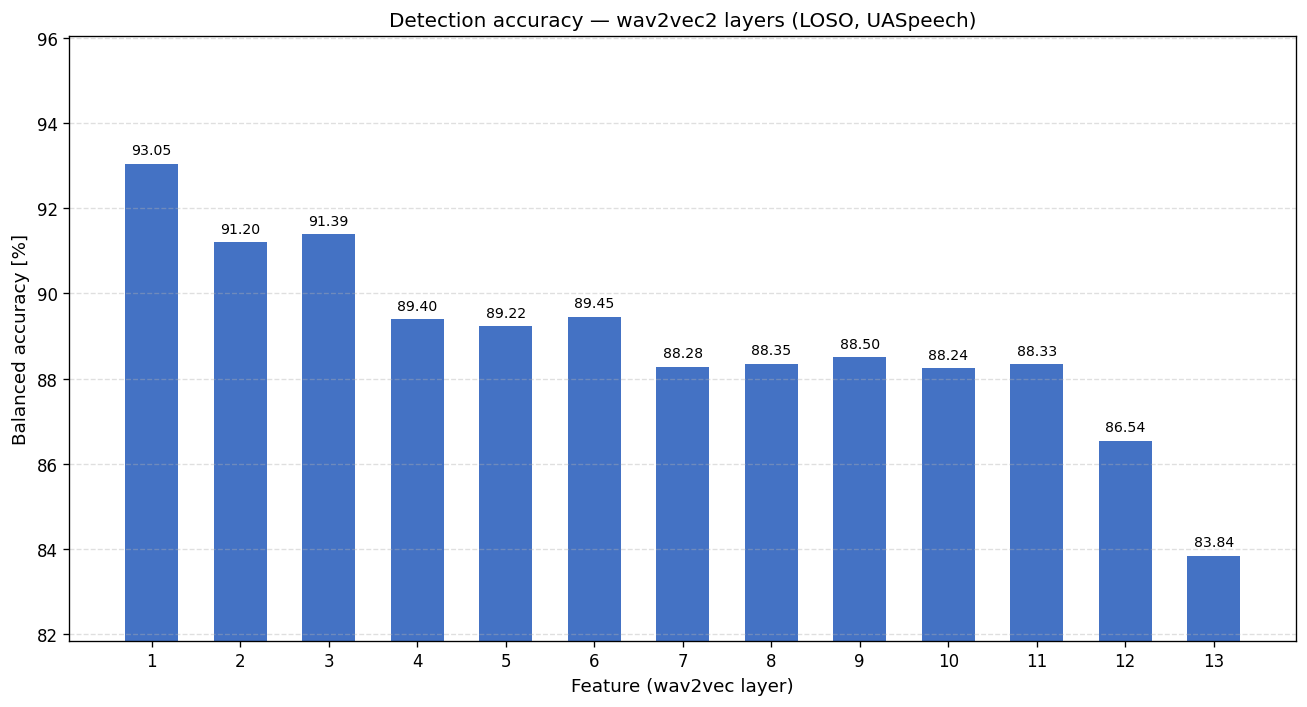

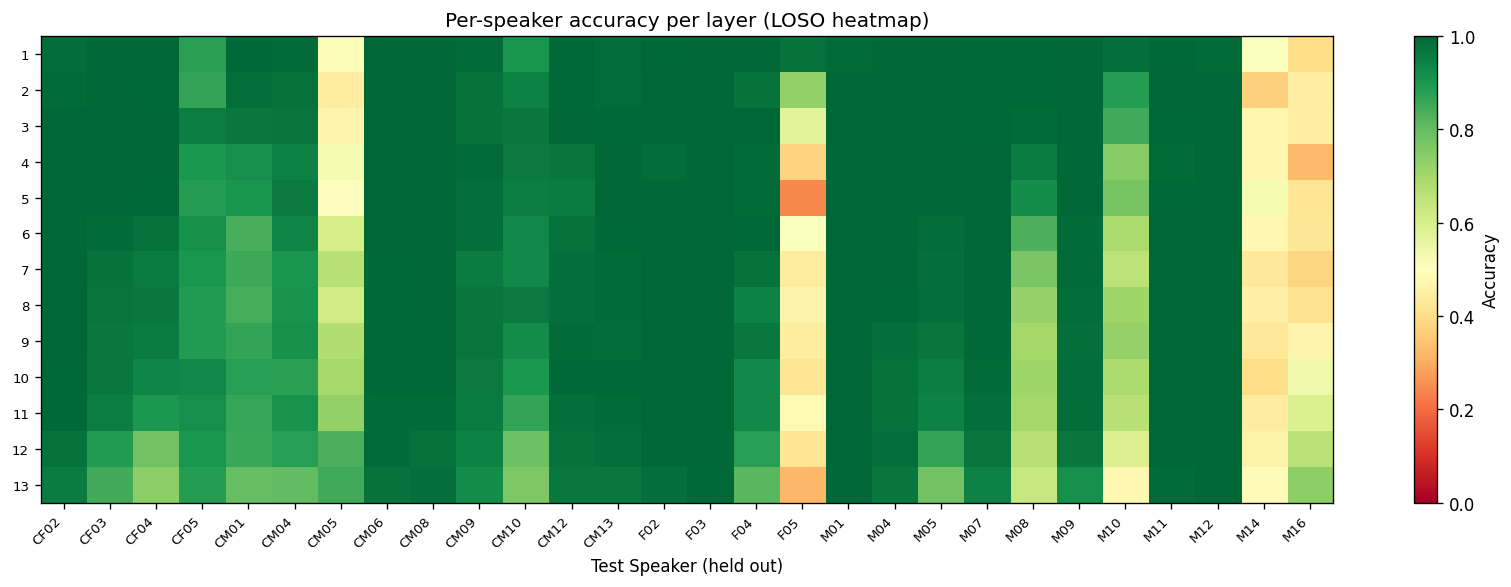

In [ ]:
cv_means = [r["cv_mean"] for r in layer_results]
x_labels = [str(i+1) for i in range(13)] 

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(range(13), [v * 100 for v in cv_means], color="#4472C4", width=0.6)

for bar, val in zip(bars, cv_means):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.15,
            f"{val*100:.2f}", ha="center", va="bottom", fontsize=8.5)

ax.set_xticks(range(13))
ax.set_xticklabels(x_labels, fontsize=10)
ax.set_xlabel("Feature (wav2vec layer)", fontsize=11)
ax.set_ylabel("Balanced accuracy [%]", fontsize=11)
ax.set_title("Detection accuracy — wav2vec2 layers (LOSO, UASpeech)", fontsize=12)
y_min = min(cv_means) * 100 - 2
y_max = max(cv_means) * 100 + 3
ax.set_ylim(y_min, y_max)
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

fig2, ax2 = plt.subplots(figsize=(14, 5))
heatmap = np.array([r["fold_accs"] for r in layer_results])  # (13, n_speakers)
im = ax2.imshow(heatmap, aspect="auto", cmap="RdYlGn", vmin=0.0, vmax=1.0, origin="upper")
ax2.set_yticks(range(13))
ax2.set_yticklabels(x_labels, fontsize=8)
ax2.set_xticks(range(len(unique_speakers)))
ax2.set_xticklabels(unique_speakers, rotation=45, ha="right", fontsize=8)
ax2.set_xlabel("Test Speaker (held out)")
ax2.set_title("Per-speaker accuracy per layer (LOSO heatmap)")
plt.colorbar(im, ax=ax2, label="Accuracy")
plt.tight_layout()
plt.show()


### 4b.  Confusion Matrix — Best Layer

Aggregated across all LOSO folds (% of total samples).


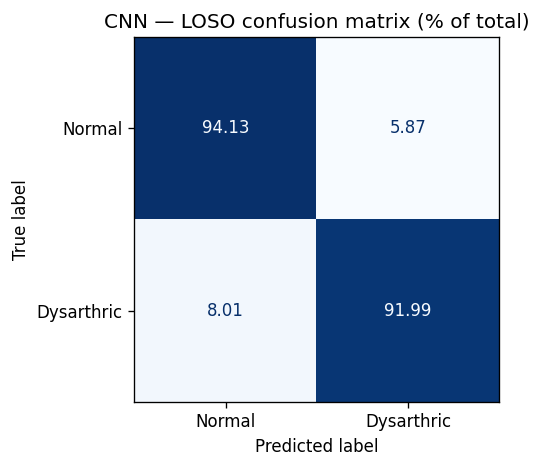

In [9]:
best = layer_results[best_layer_idx]
cm = confusion_matrix(best["all_true"], best["all_pred"], normalize="true")
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm * 100, display_labels=["Normal", "Dysarthric"]).plot(
    ax=ax, colorbar=False, cmap="Blues", values_format=".2f"
)
ax.set_title(f"{LAYER_NAMES[best_layer_idx]} — LOSO confusion matrix (% of total)")
plt.tight_layout()
plt.show()


## 6.  Comparison with MFCC Baseline

We now compare the best wav2vec2 layer against the MFCC-based classifiers
from the previous notebook. Enter your MFCC results below after running that notebook.


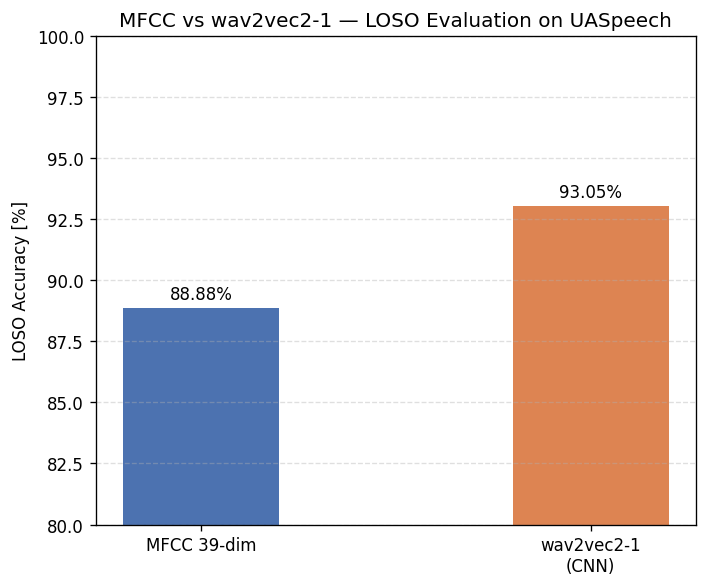

In [ ]:
MFCC_39_LOSO = 0.8888  
best_w2v     = layer_results[best_layer_idx]["cv_mean"]   

methods = ["MFCC 39-dim", "wav2vec2-1\n(CNN)"]
values  = [MFCC_39_LOSO, best_w2v]
colours = ["#4C72B0", "#DD8452"]

fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(methods, [v * 100 for v in values], color=colours, width=0.4)
ax.bar_label(bars, labels=[f"{v*100:.2f}%" for v in values], padding=3, fontsize=10)
ax.set_ylabel("LOSO Accuracy [%]")
ax.set_title("MFCC vs wav2vec2-1 — LOSO Evaluation on UASpeech")
ax.set_ylim(80, 100)
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()